In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:

from datasets import load_dataset

In [4]:
# importing data from hugging face
emotion_dataset = load_dataset('dair-ai/emotion')

In [5]:
emotion_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [6]:
train_text= emotion_dataset['train']['text']
train_label= emotion_dataset['train']['label']
test_text= emotion_dataset['test']['text']
test_label= emotion_dataset['test']['label']

In [7]:
label_names = emotion_dataset['train'].features['label'].names

In [8]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [9]:
df_train= pd.DataFrame(
    {
        'text': train_text,
        'label' : [label_names[i] for i in train_label]
    }
)

df_test= pd.DataFrame(
    {
        'text': test_text,
        'label' : [label_names[i] for i in test_label]
    }
)

In [10]:
df_train.isnull().sum()

text     0
label    0
dtype: int64

In [11]:
# EDA

In [12]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

<Axes: xlabel='label', ylabel='count'>

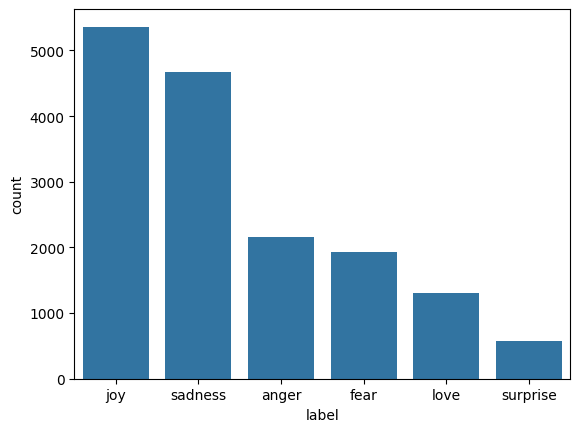

In [13]:
sns.countplot(x='label', data=df_train, order=df_train['label'].value_counts().index)

In [14]:
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


# **TOKENISATION**

In [15]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [16]:
max_words=10000

In [17]:
tokenizer = Tokenizer(num_words=max_words,oov_token='')
tokenizer.fit_on_texts(df_train['text'])

In [18]:
tokenizer.word_index

{'': 1,
 'i': 2,
 'feel': 3,
 'and': 4,
 'to': 5,
 'the': 6,
 'a': 7,
 'feeling': 8,
 'that': 9,
 'of': 10,
 'my': 11,
 'in': 12,
 'it': 13,
 'like': 14,
 'so': 15,
 'for': 16,
 'im': 17,
 'me': 18,
 'but': 19,
 'was': 20,
 'have': 21,
 'is': 22,
 'this': 23,
 'am': 24,
 'with': 25,
 'not': 26,
 'about': 27,
 'be': 28,
 'as': 29,
 'on': 30,
 'you': 31,
 'just': 32,
 'at': 33,
 'when': 34,
 'or': 35,
 'all': 36,
 'because': 37,
 'more': 38,
 'do': 39,
 'can': 40,
 'really': 41,
 'up': 42,
 't': 43,
 'are': 44,
 'by': 45,
 'very': 46,
 'know': 47,
 'been': 48,
 'if': 49,
 'out': 50,
 'myself': 51,
 'time': 52,
 'how': 53,
 'what': 54,
 'get': 55,
 'little': 56,
 'had': 57,
 'now': 58,
 'will': 59,
 'from': 60,
 'being': 61,
 'they': 62,
 'people': 63,
 'them': 64,
 'would': 65,
 'he': 66,
 'want': 67,
 'her': 68,
 'some': 69,
 'think': 70,
 'one': 71,
 'still': 72,
 'ive': 73,
 'him': 74,
 'even': 75,
 'who': 76,
 'an': 77,
 'life': 78,
 'its': 79,
 'make': 80,
 'there': 81,
 'we': 82,
 

In [19]:
train_sequence = tokenizer.texts_to_sequences(df_train["text"])
test_sequence = tokenizer.texts_to_sequences(df_test["text"])

In [20]:
padded_train_sequence = pad_sequences(train_sequence, maxlen=50, padding='post', truncating='post')
padded_test_sequence = pad_sequences(test_sequence, maxlen=50, padding='post', truncating='post')

In [21]:
train_labels = np.array(train_label)
test_labels = np.array(test_label)

In [22]:
num_classes = len(np.unique(train_labels))
num_classes

6

In [23]:
print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Max Sentence Length: {padded_train_sequence.shape[1]}")

Vocabulary Size: 15213
Max Sentence Length: 50


## Shared Training Utilities

In [24]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight= 'balanced',
    classes=np.unique(train_labels),
     y=train_labels
)

class_weights

array([0.57151022, 0.49732687, 2.04498978, 1.23513973, 1.37669936,
       4.66200466])

In [30]:
class_weight_dict = dict(enumerate(class_weights))
class_weight_dict

{0: np.float64(0.5715102157451064),
 1: np.float64(0.49732686808404825),
 2: np.float64(2.044989775051125),
 3: np.float64(1.2351397251814111),
 4: np.float64(1.3766993632765445),
 5: np.float64(4.662004662004662)}

In [25]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping= EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

### Lets train model one by one using Simple RNN, LSTM and GRU

In [26]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU

rnn_model = Sequential([
    Embedding(input_dim = max_words, output_dim =128),
    SimpleRNN(units=128, return_sequences =True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
    
])

In [33]:
rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [34]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 32ms/step - accuracy: 0.1584 - loss: 2.0416 - val_accuracy: 0.0340 - val_loss: 1.9287
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.1432 - loss: 1.8967 - val_accuracy: 0.0690 - val_loss: 1.8484
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - accuracy: 0.1322 - loss: 1.8295 - val_accuracy: 0.0505 - val_loss: 1.8085
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.1297 - loss: 1.8073 - val_accuracy: 0.0405 - val_loss: 1.7862
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.1391 - loss: 1.8066 - val_accuracy: 0.3300 - val_loss: 1.7667
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 40ms/step - accuracy: 0.1374 - loss: 1.8020 - val_accuracy: 0.2705 - val_loss: 1.7693
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 22s 44ms/step - accuracy: 0.1358 - loss: 1.7994 - val_accuracy: 0.1310 - val_loss: 1.7899
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 24s 47ms/step - accuracy: 0.1326 - loss: 1.8024 - 

In [36]:
lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim=128),
    LSTM(units=128, return_sequences = True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
]
)

In [38]:
lstm_model.compile(optimizer='adam',loss="sparse_categorical_crossentropy", metrics=['accuracy'])

In [40]:
lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data =(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 58s 103ms/step - accuracy: 0.1686 - loss: 1.7944 - val_accuracy: 0.1375 - val_loss: 1.8003
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 50s 99ms/step - accuracy: 0.1603 - loss: 1.7947 - val_accuracy: 0.1395 - val_loss: 1.7959
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 50s 99ms/step - accuracy: 0.1538 - loss: 1.7896 - val_accuracy: 0.1960 - val_loss: 1.7916


In [41]:
lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.1375 - loss: 1.8003
LSTM Loss: 1.8003114461898804
LSTM Accuracy: 0.13750000298023224


In [42]:
gru_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 51s 89ms/step - accuracy: 0.1423 - loss: 1.7972 - val_accuracy: 0.1405 - val_loss: 1.7903
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 44s 88ms/step - accuracy: 0.1387 - loss: 1.7957 - val_accuracy: 0.2805 - val_loss: 1.7893
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 43s 85ms/step - accuracy: 0.1538 - loss: 1.7941 - val_accuracy: 0.1395 - val_loss: 1.7315
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 43s 86ms/step - accuracy: 0.1582 - loss: 1.7941 - val_accuracy: 0.2865 - val_loss: 1.7864
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 46s 92ms/step - accuracy: 0.1730 - loss: 1.7903 - val_accuracy: 0.0410 - val_loss: 1.7880
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 46s 91ms/step - accuracy: 0.1656 - loss: 1.7835 - val_accuracy: 0.3365 - val_loss: 1.7609
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.1395 - loss: 1.7315
GRU Loss: 1.7314724922180176
GRU Accuracy: 0.13950000703334808


### Bidirectional GRU

In [43]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim = max_words, output_dim = 300 , input_length = 50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax') #Output Layer
])

BiGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

BiGRU.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_1 (Bidirectional)      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [44]:
BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 122s 216ms/step - accuracy: 0.5349 - loss: 1.1375 - val_accuracy: 0.8835 - val_loss: 0.3907
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 104s 207ms/step - accuracy: 0.9121 - loss: 0.2708 - val_accuracy: 0.9140 - val_loss: 0.2599
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 103s 205ms/step - accuracy: 0.9466 - loss: 0.1527 - val_accuracy: 0.9240 - val_loss: 0.2144
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 109s 217ms/step - accuracy: 0.9619 - loss: 0.1074 - val_accuracy: 0.9210 - val_loss: 0.2974
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 104s 208ms/step - accuracy: 0.9656 - loss: 0.0984 - val_accuracy: 0.9200 - val_loss: 0.2591
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 103s 206ms/step - accuracy: 0.9751 - loss: 0.0735 - val_accuracy: 0.9220 - val_loss: 0.2823


In [45]:
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(padded_test_sequence, test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - accuracy: 0.9240 - loss: 0.2144
BiGRU Loss: 0.2143612951040268
BiGRU Accuracy: 0.9240000247955322


### Overall Evaluation & Bias Analysis

63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step


<Axes: >

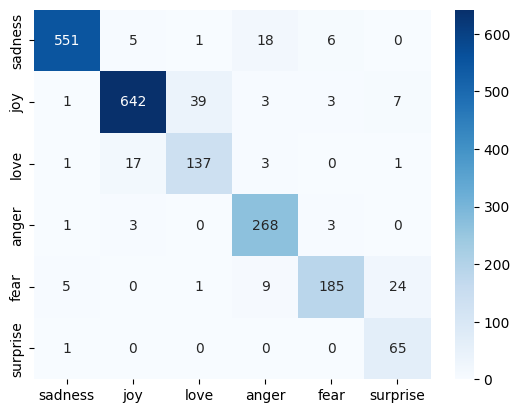

In [47]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequence),axis=1)

sns.heatmap(confusion_matrix(test_label, BiGRU_predictions),annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)


### Final Predictions

In [50]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')
    

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: joy
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


### Save Model & Tokenizer

In [54]:
import os
import pickle

# Create directory to store artifacts
model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True)

# Save the BiGRU model
BiGRU.save(os.path.join(model_dir, 'BiGRU_Model.keras'))

# Save the tokenizer
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
    pickle.dump(tokenizer, file)

print("BiGRU model and tokenizer saved successfully!")

BiGRU model and tokenizer saved successfully!
